# University Student Clustering and Classification



In [1]:
import os
import json
import sqlite3
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas: 2.2.3
Scikit-learn: 1.8.0


## 1. Load the Three Datasets

In [2]:
data_files = ["students.xlsx", "faculty.xlsx", "admin_records.xlsx"]
if not all(os.path.exists(file) for file in data_files):
    try:
        from google.colab import files
        uploaded = files.upload()
    except ImportError:
        raise FileNotFoundError("Place students.xlsx, faculty.xlsx and admin_records.xlsx beside this notebook.")

students_df = pd.read_excel("students.xlsx")
faculty_df = pd.read_excel("faculty.xlsx")
admin_df = pd.read_excel("admin_records.xlsx")
print("Students:", students_df.shape)
print("Faculty:", faculty_df.shape)
print("Admin records:", admin_df.shape)
display(students_df.head())
display(faculty_df.head())
display(admin_df.head())

Students: (450, 6)
Faculty: (450, 8)
Admin records: (20, 5)


,student_id,student_name,department,age,semester,cgpa
0,STU0001,Student 001,Computer Science,18,1,3.49
1,STU0002,Student 002,Electrical Engineering,18,4,2.77
2,STU0003,Student 003,Data Science,19,4,3.12
3,STU0004,Student 004,Data Science,25,8,2.99
4,STU0005,Student 005,Electrical Engineering,22,2,2.21


,student_id,faculty_id,course_code,course_name,marks,attendance_pct,fee_amount,fee_status
0,STU0001,FAC020,BA210,Artificial Intelligence,90.67,95.81,55000,Paid
1,STU0002,FAC019,DS301,Machine Learning,83.07,84.41,45000,Paid
2,STU0003,FAC019,BA210,Programming,77.29,93.92,60000,Partial
3,STU0004,FAC018,CS220,Machine Learning,77.28,83.82,55000,Paid
4,STU0005,FAC013,CS220,Statistics,67.63,60.78,50000,Paid


,faculty_id,faculty_name,designation,experience_years,salary
0,FAC001,Faculty Member 01,Lecturer,22,71369
1,FAC002,Faculty Member 02,Assistant Professor,10,128431
2,FAC003,Faculty Member 03,Lecturer,12,107485
3,FAC004,Faculty Member 04,Associate Professor,16,231373
4,FAC005,Faculty Member 05,Associate Professor,7,164313


## 2. Store Data in SQLite

In [3]:
conn = sqlite3.connect("university_management.db")
students_df.to_sql("students", conn, index=False, if_exists="replace")
faculty_df.to_sql("faculty", conn, index=False, if_exists="replace")
admin_df.to_sql("admin_records", conn, index=False, if_exists="replace")
pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;", conn)

,name
0,admin_records
1,faculty
2,students


## 3. SQL JOIN

In [4]:
query = """
SELECT
    s.student_id, s.student_name, s.department, s.age, s.semester, s.cgpa,
    a.course_code, a.course_name, a.marks, a.attendance_pct, a.fee_amount, a.fee_status,
    f.faculty_id, f.faculty_name, f.designation, f.experience_years, f.salary
FROM students AS s
INNER JOIN faculty AS a ON s.student_id = a.student_id
INNER JOIN admin_records AS f ON a.faculty_id = f.faculty_id
ORDER BY s.student_id
"""
joined_df = pd.read_sql_query(query, conn)
print("Joined Data Shape:", joined_df.shape)
display(joined_df.head())

Joined Data Shape: (450, 17)


,student_id,student_name,department,age,semester,cgpa,course_code,course_name,marks,attendance_pct,fee_amount,fee_status,faculty_id,faculty_name,designation,experience_years,salary
0,STU0001,Student 001,Computer Science,18,1,3.49,BA210,Artificial Intelligence,90.67,95.81,55000,Paid,FAC020,Faculty Member 20,Assistant Professor,17,88958
1,STU0002,Student 002,Electrical Engineering,18,4,2.77,DS301,Machine Learning,83.07,84.41,45000,Paid,FAC019,Faculty Member 19,Associate Professor,23,97772
2,STU0003,Student 003,Data Science,19,4,3.12,BA210,Programming,77.29,93.92,60000,Partial,FAC019,Faculty Member 19,Associate Professor,23,97772
3,STU0004,Student 004,Data Science,25,8,2.99,CS220,Machine Learning,77.28,83.82,55000,Paid,FAC018,Faculty Member 18,Lecturer,1,104627
4,STU0005,Student 005,Electrical Engineering,22,2,2.21,CS220,Statistics,67.63,60.78,50000,Paid,FAC013,Faculty Member 13,Lecturer,11,183768


## 4. Data Cleaning and Preprocessing

In [5]:
features = ["age", "semester", "cgpa", "marks", "attendance_pct"]
X = joined_df[features].copy()
print("Missing values before cleaning:")
display(X.isnull().sum().to_frame("Missing Values"))

imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=features)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
print("Missing values after cleaning:", int(X_imputed.isnull().sum().sum()))
print("Scaled data shape:", X_scaled.shape)

Missing values before cleaning:


,Missing Values
age,0
semester,0
cgpa,5
marks,6
attendance_pct,5


Missing values after cleaning: 0
Scaled data shape: (450, 5)


## 5. K-Means Clustering and Elbow Method

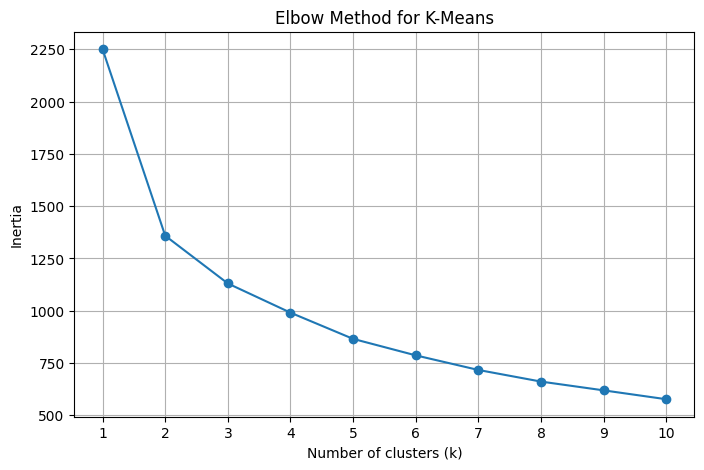

In [6]:
k_values = range(1, 11)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=GLOBAL_SEED, n_init=20)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [7]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=GLOBAL_SEED, n_init=20)
joined_df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)
kmeans_silhouette = silhouette_score(X_scaled, joined_df["KMeans_Cluster"])
print("Selected k:", optimal_k)
print("K-Means Silhouette Score:", round(kmeans_silhouette, 4))
print("K-Means cluster counts:")
display(joined_df["KMeans_Cluster"].value_counts().sort_index())
display(joined_df.groupby("KMeans_Cluster")[features].mean().round(2))

Selected k: 3
K-Means Silhouette Score: 0.273
K-Means cluster counts:


KMeans_Cluster
0    170
1    131
2    149
Name: count, dtype: int64

,age,semester,cgpa,marks,attendance_pct
KMeans_Cluster,,,,,
0,22.15,4.16,2.15,60.71,68.61
1,22.53,6.67,3.26,80.39,87.19
2,21.79,2.62,3.35,85.52,88.57


## 6. DBSCAN and Hyperparameter Tuning

In [8]:
eps_values = [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.8, 2.0]
min_samples_values = [5, 10, 15]
dbscan_results = []
for eps in eps_values:
    for min_samples in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        cluster_count = len(set(labels) - {-1})
        noise_count = int(np.sum(labels == -1))
        non_noise = labels != -1
        score = silhouette_score(X_scaled[non_noise], labels[non_noise]) if cluster_count >= 2 and non_noise.sum() > cluster_count else np.nan
        dbscan_results.append({"eps": eps, "min_samples": min_samples, "clusters": cluster_count, "noise_points": noise_count, "silhouette": score})
dbscan_trials_df = pd.DataFrame(dbscan_results)
display(dbscan_trials_df)

,eps,min_samples,clusters,noise_points,silhouette
0,0.7,5,15,297,0.287328
1,0.7,10,0,450,NaN
2,0.7,15,0,450,NaN
3,0.8,5,8,167,0.067729
4,0.8,10,7,371,0.402346
5,0.8,15,0,450,NaN
6,0.9,5,4,72,0.217499
7,0.9,10,5,244,0.228920
8,0.9,15,1,435,NaN
9,1.0,5,1,26,NaN


In [9]:
valid_trials = dbscan_trials_df[(dbscan_trials_df["clusters"] >= 2) & (dbscan_trials_df["noise_points"] < len(joined_df) * 0.5) & dbscan_trials_df["silhouette"].notna()]
if len(valid_trials):
    selected_trial = valid_trials.sort_values(["silhouette", "noise_points"], ascending=[False, True]).iloc[0]
else:
    selected_trial = dbscan_trials_df.sort_values(["clusters", "noise_points"], ascending=[False, True]).iloc[0]
best_eps = float(selected_trial["eps"])
best_min_samples = int(selected_trial["min_samples"])
dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
joined_df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)
dbscan_cluster_count = len(set(joined_df["DBSCAN_Cluster"]) - {-1})
dbscan_noise_count = int((joined_df["DBSCAN_Cluster"] == -1).sum())
dbscan_non_noise = joined_df["DBSCAN_Cluster"] != -1
dbscan_silhouette = silhouette_score(X_scaled[dbscan_non_noise], joined_df.loc[dbscan_non_noise, "DBSCAN_Cluster"]) if dbscan_cluster_count >= 2 and dbscan_non_noise.sum() > dbscan_cluster_count else np.nan
print("Selected eps:", best_eps)
print("Selected min_samples:", best_min_samples)
print("DBSCAN clusters:", dbscan_cluster_count)
print("DBSCAN noise points:", dbscan_noise_count)
print("DBSCAN Silhouette Score (excluding noise):", dbscan_silhouette)
display(joined_df["DBSCAN_Cluster"].value_counts().sort_index())

Selected eps: 1.0
Selected min_samples: 10
DBSCAN clusters: 2
DBSCAN noise points: 91
DBSCAN Silhouette Score (excluding noise): 0.38909038300381477


DBSCAN_Cluster
-1     91
 0    240
 1    119
Name: count, dtype: int64

## 7. PCA Cluster Visualization

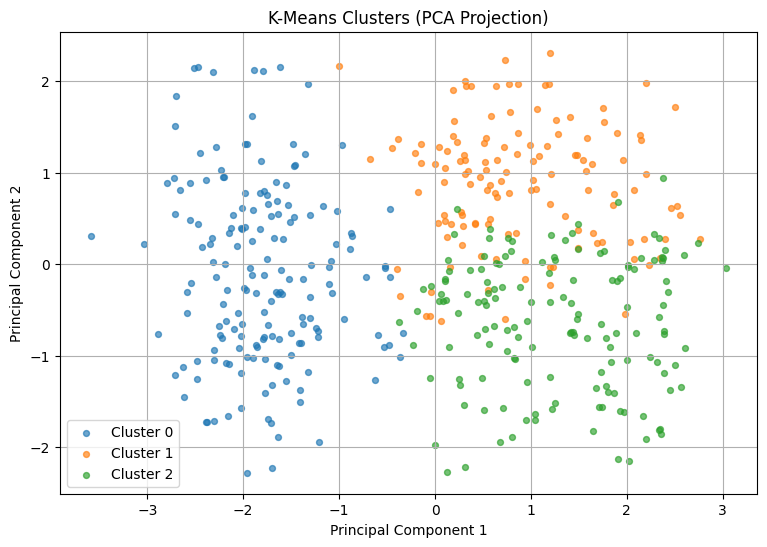

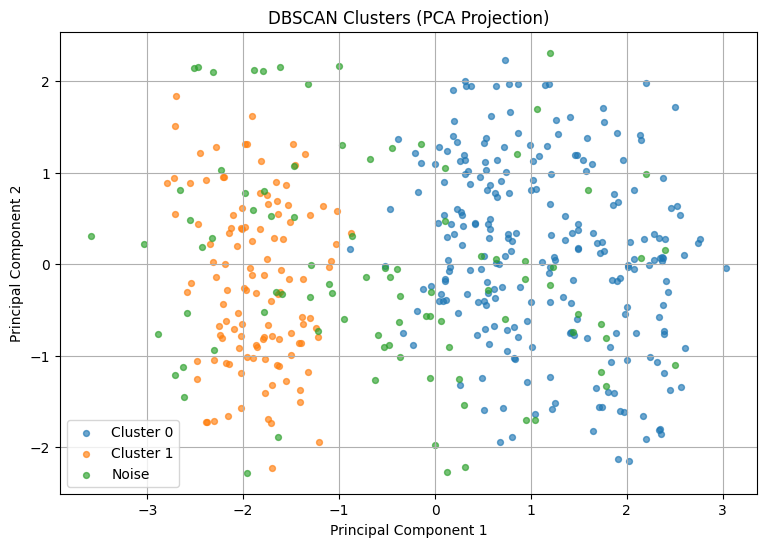

Explained variance: [0.504 0.204]


In [10]:
pca = PCA(n_components=2, random_state=GLOBAL_SEED)
X_pca = pca.fit_transform(X_scaled)
plot_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
plot_df["KMeans_Cluster"] = joined_df["KMeans_Cluster"].astype(str)
plot_df["DBSCAN_Cluster"] = joined_df["DBSCAN_Cluster"].astype(str)

plt.figure(figsize=(9, 6))
for label in sorted(plot_df["KMeans_Cluster"].unique()):
    subset = plot_df[plot_df["KMeans_Cluster"] == label]
    plt.scatter(subset["PC1"], subset["PC2"], s=18, alpha=0.65, label="Cluster " + label)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters (PCA Projection)")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 6))
for label in sorted(plot_df["DBSCAN_Cluster"].unique(), key=lambda x: (x == "-1", x)):
    subset = plot_df[plot_df["DBSCAN_Cluster"] == label]
    label_name = "Noise" if label == "-1" else "Cluster " + label
    plt.scatter(subset["PC1"], subset["PC2"], s=18, alpha=0.65, label=label_name)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clusters (PCA Projection)")
plt.legend()
plt.grid(True)
plt.show()
print("Explained variance:", np.round(pca.explained_variance_ratio_, 3))

## 8. Cluster Profiles

In [11]:
print("K-Means cluster profile:")
display(joined_df.groupby("KMeans_Cluster")[features].mean().round(2))
print("K-Means cluster sizes:")
display(joined_df["KMeans_Cluster"].value_counts().sort_index())
print("DBSCAN cluster sizes (including -1 noise):")
display(joined_df["DBSCAN_Cluster"].value_counts().sort_index())
joined_df.to_sql("clustering_results", conn, index=False, if_exists="replace")
joined_df.to_excel("joined_clustering_results.xlsx", index=False)

K-Means cluster profile:


,age,semester,cgpa,marks,attendance_pct
KMeans_Cluster,,,,,
0,22.15,4.16,2.15,60.71,68.61
1,22.53,6.67,3.26,80.39,87.19
2,21.79,2.62,3.35,85.52,88.57


K-Means cluster sizes:


KMeans_Cluster
0    170
1    131
2    149
Name: count, dtype: int64

DBSCAN cluster sizes (including -1 noise):


DBSCAN_Cluster
-1     91
 0    240
 1    119
Name: count, dtype: int64

## 9. Classification Using K-Means Labels

In [12]:
X_cls = joined_df[features].copy()
y_cls = joined_df["KMeans_Cluster"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=GLOBAL_SEED, stratify=y_cls
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, features)
])

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=GLOBAL_SEED),
    "Decision Tree": DecisionTreeClassifier(random_state=GLOBAL_SEED),
    "Random Forest": RandomForestClassifier(random_state=GLOBAL_SEED, n_estimators=150)
}
comparison = []
pipelines = {}
for name, classifier in classifiers.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", classifier)])
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)
    pipelines[name] = pipe
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1-score": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })
comparison_df = pd.DataFrame(comparison).sort_values("F1-score", ascending=False)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,1.0000,1.0000,1.0000,1.0000
2,Random Forest,0.9778,0.9792,0.9778,0.9778
1,Decision Tree,0.9111,0.9141,0.9111,0.9105


## 10. Hyperparameter Tuning

In [13]:
best_name = comparison_df.iloc[0]["Model"]
if best_name == "Logistic Regression":
    base_model = LogisticRegression(max_iter=2000, random_state=GLOBAL_SEED)
    param_grid = {"classifier__C": [0.1, 1, 5, 10], "classifier__solver": ["lbfgs"]}
elif best_name == "Decision Tree":
    base_model = DecisionTreeClassifier(random_state=GLOBAL_SEED)
    param_grid = {"classifier__max_depth": [3, 5, 8, None], "classifier__min_samples_split": [2, 5, 10]}
else:
    base_model = RandomForestClassifier(random_state=GLOBAL_SEED)
    param_grid = {"classifier__n_estimators": [100, 150, 250], "classifier__max_depth": [None, 5, 10], "classifier__min_samples_split": [2, 5]}

tuning_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", base_model)])
grid_search = GridSearchCV(tuning_pipeline, param_grid, cv=5, scoring="f1_weighted", n_jobs=-1)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print("Best Model:", best_name)
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-validation F1:", round(grid_search.best_score_, 4))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best Model: Logistic Regression
Best Parameters: {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Best Cross-validation F1: 0.9917


## 11. Final Evaluation

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        34
           1       1.00      1.00      1.00        26
           2       1.00      1.00      1.00        30

    accuracy                           1.00        90
   macro avg       1.00      1.00      1.00        90
weighted avg       1.00      1.00      1.00        90

Confusion Matrix:


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,Predicted 0,Predicted 1,Predicted 2
Actual 0,34,0,0
Actual 1,0,26,0
Actual 2,0,0,30


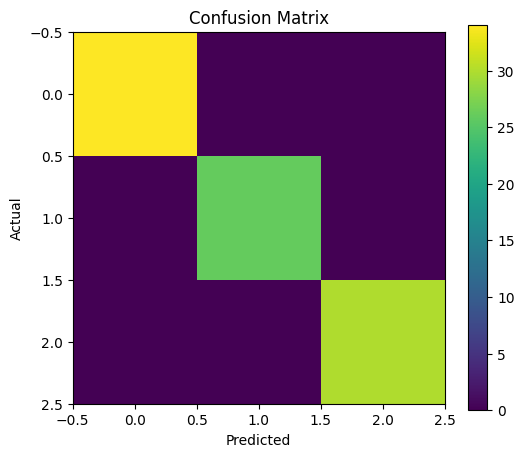

In [14]:
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
display(pd.DataFrame(cm, index=[f"Actual {i}" for i in sorted(y_cls.unique())], columns=[f"Predicted {i}" for i in sorted(y_cls.unique())]))
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

## 12. Save and Load the Model

In [15]:
model_path = "student_cluster_classifier.joblib"
joblib.dump(best_model, model_path)
loaded_model = joblib.load(model_path)
loaded_predictions = loaded_model.predict(X_test.iloc[:10])
original_predictions = best_model.predict(X_test.iloc[:10])
np.testing.assert_array_equal(loaded_predictions, original_predictions)
print("Model saved:", model_path)
print("Assertion Passed: Loaded model predictions match original predictions.")
display(pd.DataFrame({"Original": original_predictions, "Loaded": loaded_predictions}))

Model saved: student_cluster_classifier.joblib
Assertion Passed: Loaded model predictions match original predictions.


,Original,Loaded
0,2,2
1,0,0
2,1,1
3,2,2
4,1,1
5,2,2
6,2,2
7,1,1
8,1,1
9,0,0


## 13. Input Schema Validation

In [16]:
SCHEMA = {
    "columns": features,
    "types": {"age": "numeric", "semester": "numeric", "cgpa": "numeric", "marks": "numeric", "attendance_pct": "numeric"},
    "domain": {
        "age": {"min": 16, "max": 60},
        "semester": {"min": 1, "max": 16},
        "cgpa": {"min": 0, "max": 4},
        "marks": {"min": 0, "max": 100},
        "attendance_pct": {"min": 0, "max": 100}
    }
}
with open("schema.json", "w") as file:
    json.dump(SCHEMA, file, indent=4)

def validate_payload(df_input, schema=SCHEMA):
    missing_cols = set(schema["columns"]) - set(df_input.columns)
    extra_cols = set(df_input.columns) - set(schema["columns"])
    if missing_cols:
        raise ValueError(f"Missing required columns: {sorted(missing_cols)}")
    if extra_cols:
        raise ValueError(f"Unexpected columns: {sorted(extra_cols)}")
    df_validated = df_input[schema["columns"]].copy()
    for col in schema["columns"]:
        if not pd.api.types.is_numeric_dtype(df_validated[col]):
            raise TypeError(f"Column '{col}' must contain numeric values.")
        if df_validated[col].isnull().any():
            raise ValueError(f"Column '{col}' contains missing values.")
        limits = schema["domain"][col]
        if not df_validated[col].between(limits["min"], limits["max"]).all():
            raise ValueError(f"Values in '{col}' must be between {limits['min']} and {limits['max']}.")
    return df_validated.astype(float)

new_student = pd.DataFrame([{"age": 21, "semester": 6, "cgpa": 3.25, "marks": 82, "attendance_pct": 88}])
validated_student = validate_payload(new_student)
print("Validated Input:")
display(validated_student)
print("Predicted Cluster:", int(loaded_model.predict(validated_student)[0]))

Validated Input:


,age,semester,cgpa,marks,attendance_pct
0,21.0,6.0,3.25,82.0,88.0


Predicted Cluster: 1


## 14. Input Validation Tests

In [17]:
try:
    validate_payload(new_student.drop(columns=["cgpa"]))
except ValueError as error:
    print("Missing column caught:", error)

try:
    invalid_type = new_student.copy()
    invalid_type["cgpa"] = "high"
    validate_payload(invalid_type)
except TypeError as error:
    print("Incorrect data type caught:", error)

try:
    invalid_value = new_student.copy()
    invalid_value["attendance_pct"] = 150
    validate_payload(invalid_value)
except ValueError as error:
    print("Invalid value caught:", error)

Missing column caught: Missing required columns: ['cgpa']
Incorrect data type caught: Column 'cgpa' must contain numeric values.
Invalid value caught: Values in 'attendance_pct' must be between 0 and 100.


## 15. Prediction Consistency and Input Drift

In [18]:
baseline_predictions = loaded_model.predict(X_test)
repeat_predictions = loaded_model.predict(X_test)
np.testing.assert_array_equal(baseline_predictions, repeat_predictions)
print("Prediction consistency check passed.")

drifted_df = X_test.copy()
drifted_df["marks"] = np.clip(drifted_df["marks"] + 15, 0, 100)
baseline_distribution = pd.Series(baseline_predictions).value_counts(normalize=True).sort_index()
drift_distribution = pd.Series(loaded_model.predict(drifted_df)).value_counts(normalize=True).sort_index()
drift_check = pd.concat([baseline_distribution, drift_distribution], axis=1).fillna(0)
drift_check.columns = ["Baseline Prediction Share", "Drifted Prediction Share"]
display(drift_check.round(3))
print("Average baseline cluster:", round(float(np.mean(baseline_predictions)), 3))
print("Average drifted cluster:", round(float(loaded_model.predict(drifted_df).mean()), 3))

Prediction consistency check passed.


,Baseline Prediction Share,Drifted Prediction Share
0,0.378,0.333
1,0.289,0.300
2,0.333,0.367


Average baseline cluster: 0.956
Average drifted cluster: 1.033


## 16. Save Final Results

In [19]:
joined_df.to_csv("student_clustering_results.csv", index=False)
metrics = {"model": best_name, "best_parameters": grid_search.best_params_, "accuracy": accuracy, "precision": precision, "recall": recall, "f1_score": f1, "kmeans_silhouette": kmeans_silhouette, "dbscan_silhouette_excluding_noise": None if pd.isna(dbscan_silhouette) else float(dbscan_silhouette), "dbscan_eps": best_eps, "dbscan_min_samples": best_min_samples}
with open("evaluation_metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)
conn.close()
print("Project files saved successfully.")

Project files saved successfully.
